# Eksperimen Peramalan & Sistem Peringatan Dini: Bawang Putih Sinco/Honan
Notebook ini mendokumentasikan alur lengkap peramalan harga pangan Kota Surabaya khusus untuk **Bawang Putih Sinco/Honan** secara komprehensif (E0–E6):

| Langkah | Model / Fokus | Tier | Tujuan & Estimasi CPU |
|---|---|:---:|---|
| **🔬 E0 — EDA & Diagnostik** | Uji ADF, ACF/PACF, STL | — | Karakterisasi stokastik & stasioneritas deret waktu |
| **🧱 Inspeksi Matriks ML** | Whitelist Fitur & Target | — | Menjamin *Zero Lookahead Bias* & tanpa *Target Leakage* |
| **📊 E1 — Sanity Baseline** | Naive Last Value + 7-Day SMA | 4 | Menetapkan garis batas minimum akurasi (< 1 dtk) |
| **📈 E2 — Statistical Baseline** | AutoARIMA + AutoETS (via StatsForecast) | 4 | Membuktikan keunggulan ML atas statistik klasik (~45 dtk) |
| **📐 E3 — Linear ML Baseline** | Ridge Regression (Global) | 2 | Membuktikan fitur tabular mengandung sinyal prediktif (< 3 dtk) |
| **🤖 E4 — GBDT Komparasi** | LightGBM vs XGBoost vs CatBoost | 1 | Memilih model GBDT terbaik dengan regresi kuantil 80% (< 30 dtk) |
| **🧪 E5 — Studi Ablasi Fitur** | Model GBDT Terbaik (± Cuaca, ± Kalender) | 1 | Menguji signifikansi data BMKG & kalender libur (< 15 dtk) |
| **🚨 E6 — Kalibrasi & Evaluasi EWS** | Komposit 20-20-20-40 & Uji SOP | — | Mengukur Recall (≥90%), FAR (≤20%), & Lead Time (< 5 dtk) |


In [1]:
import sys
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

# Pastikan root direktori proyek masuk ke sys.path agar modul src/ dapat diimpor
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

# Import modul core dari src/
from src.models.backtest import resolve_commodity
from src.analytics.features import load_raw_datasets, build_supervised_dataset
from src.models.forecast_engine import run_experiment, ForecastEngine
from src.analytics.metrics import plot_residual_diagnostics
from src.safety.early_warning import generate_ews_summary_dataframe, evaluate_ews_performance

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

KOMODITAS = "Bawang Putih Sinco/Honan"
KOMODITAS_ID, CANONICAL_NAME = resolve_commodity(KOMODITAS)
print(f"Komoditas Terpilih : {CANONICAL_NAME}")
print(f"ID Komoditas       : {KOMODITAS_ID}")


Komoditas Terpilih : Bawang Putih Sinco/Honan
ID Komoditas       : 49


## 🔬 E0 — Forecasting-Specific EDA & Time-Series Diagnostics
Sebelum melatih model, kita menguji sifat stokastik dari deret waktu harga komoditas ini:
1. **Uji Augmented Dickey-Fuller (ADF)** untuk menguji stasioneritas harga.
2. **Plot ACF & PACF** untuk mengidentifikasi lag autoregresif dominan.
3. **Dekomposisi Deret Waktu (Trend, Seasonal, Residual)**.

In [2]:
# Muat dataset harga harian
df_harga, df_kal, df_cuaca = load_raw_datasets()

# Filter data khusus komoditas ini
df_kom = df_harga[df_harga["komoditas_id"] == KOMODITAS_ID].sort_values("tanggal")

# Ekstrak seri harian harga_imputasi di Pasar Keputran (grosir, ID: 5) dan Wonokromo (eceran, ID: 2)
seri_keputran = df_kom[df_kom["pasar_id"] == 5].set_index("tanggal")["harga_imputasi"].dropna()
seri_wonokromo = df_kom[df_kom["pasar_id"] == 2].set_index("tanggal")["harga_imputasi"].dropna()

# Fallback jika pasar 5 atau 2 kosong
if seri_keputran.empty or seri_wonokromo.empty:
    avail_pasars = df_kom["pasar_id"].unique()
    if len(avail_pasars) >= 2:
        seri_keputran = df_kom[df_kom["pasar_id"] == avail_pasars[0]].set_index("tanggal")["harga_imputasi"].dropna()
        seri_wonokromo = df_kom[df_kom["pasar_id"] == avail_pasars[1]].set_index("tanggal")["harga_imputasi"].dropna()

print(f"Total observasi harian: {len(df_kom):,} baris")
print(f"Observasi Pasar Keputran  : {len(seri_keputran):,} hari")
print(f"Observasi Pasar Wonokromo : {len(seri_wonokromo):,} hari")


Total observasi harian: 13,747 baris
Observasi Pasar Keputran  : 2,459 hari
Observasi Pasar Wonokromo : 2,459 hari


In [3]:
# 1. Uji Stasioneritas (Augmented Dickey-Fuller)
def adf_test(series, title=""):
    result = adfuller(series.dropna(), autolag="AIC")
    print(f"=== Uji ADF: {title} ===")
    print(f"ADF Statistic : {result[0]:.4f}")
    print(f"p-value       : {result[1]:.4e}")
    print("Critical Values:")
    for key, value in result[4].items():
        print(f"   {key}: {value:.4f}")
    if result[1] <= 0.05:
        print("-> Kesimpulan : Stasioner (Tolak H0)")
    else:
        print("-> Kesimpulan : Non-Stasioner (Gagal Tolak H0 - Butuh Differencing/Lag)")

if not seri_keputran.empty:
    adf_test(seri_keputran, f"{CANONICAL_NAME} (Pasar Keputran)")
if not seri_wonokromo.empty:
    print()
    adf_test(seri_wonokromo, f"{CANONICAL_NAME} (Pasar Wonokromo)")


C:\Users\USER\AppData\Local\Temp\ipykernel_52556\4258733441.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")


=== Uji ADF: Bawang Putih Sinco/Honan (Pasar Keputran) ===
ADF Statistic : -2.5152
p-value       : 1.1181e-01
Critical Values:
   1%: -3.4330
   5%: -2.8627
   10%: -2.5674
-> Kesimpulan : Non-Stasioner (Gagal Tolak H0 - Butuh Differencing/Lag)

=== Uji ADF: Bawang Putih Sinco/Honan (Pasar Wonokromo) ===
ADF Statistic : -2.2210
p-value       : 1.9871e-01
Critical Values:
   1%: -3.4330
   5%: -2.8627
   10%: -2.5674
-> Kesimpulan : Non-Stasioner (Gagal Tolak H0 - Butuh Differencing/Lag)


C:\Users\USER\AppData\Local\Temp\ipykernel_52556\4258733441.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")


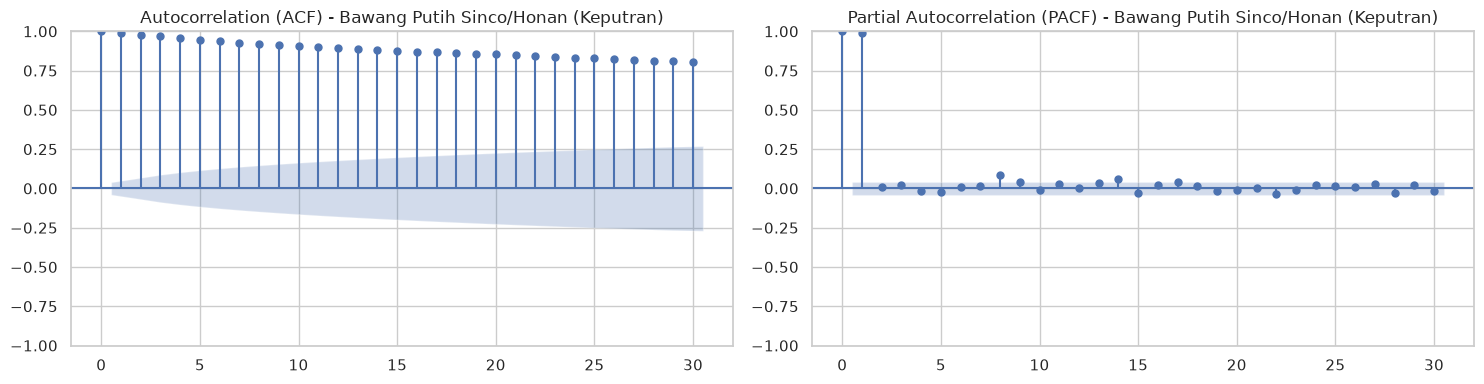

In [4]:
# 2. Plot ACF & PACF untuk mengidentifikasi lag autoregresif & musiman
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
if not seri_keputran.empty:
    plot_acf(seri_keputran, lags=30, ax=axes[0], title=f"Autocorrelation (ACF) - {CANONICAL_NAME} (Keputran)")
    plot_pacf(seri_keputran, lags=30, ax=axes[1], title=f"Partial Autocorrelation (PACF) - {CANONICAL_NAME} (Keputran)")
    plt.tight_layout()
    plt.show()


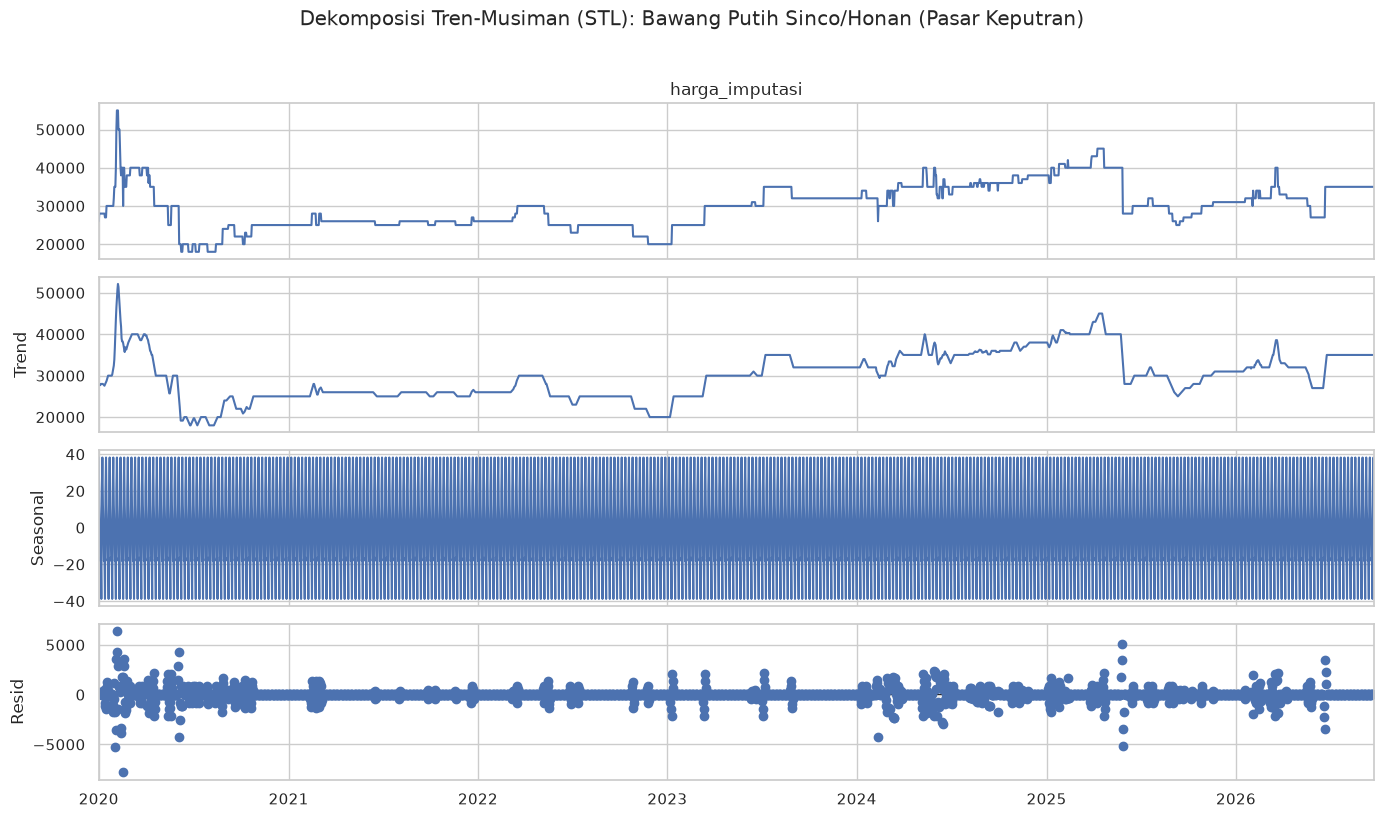

In [5]:
# 3. Dekomposisi Deret Waktu (Trend, Seasonal 7-Hari, Residual)
if len(seri_keputran) > 60:
    seri_daily = seri_keputran.asfreq("D").ffill()
    decomp = seasonal_decompose(seri_daily, model="additive", period=7)
    fig = decomp.plot()
    fig.set_size_inches(14, 8)
    plt.suptitle(f"Dekomposisi Tren-Musiman (STL): {CANONICAL_NAME} (Pasar Keputran)", y=1.02)
    plt.tight_layout()
    plt.show()


## 🧱 Inspeksi Matriks Fitur Supervised Machine Learning
Sebelum melatih model, kita menginspeksi matriks tabular fitur yang disuapkan ke model:
* Memastikan **Zero Lookahead Bias** (semua fitur lag dan rolling strictly left-aligned via `.shift(1)`).
* Memisahkan kolom target `target_price` dari matriks prediktor $X$.
* Mengonfirmasi bahwa metadata string dan kolom target delta dibuang agar tidak terjadi *target leakage*.

In [6]:
# Bangun dataset supervised dengan horizon H+7
df_inspect = build_supervised_dataset(horizon=7, komoditas_id=KOMODITAS_ID, include_weather=True)

# Whitelist prediktor aktual
feature_cols = [
    "pasar_id", "price_current", "price_lag_1", "price_lag_2", "price_lag_3",
    "price_lag_7", "price_lag_14", "rolling_mean_7d", "rolling_std_7d",
    "rolling_mean_14d", "rolling_std_14d", "pct_change_1d", "pct_change_7d",
    "target_bulan", "target_is_weekend", "target_is_libur_nasional",
    "target_is_ramadan", "target_is_pra_ramadan", 
    "curah_hujan_mm", "rain_sum_7d", "rain_sum_14d", "rain_lag_28d"
]
feature_cols = [c for c in feature_cols if c in df_inspect.columns]

identitas = ["tanggal", "pasar_id", "komoditas_id"]
target = ["target_price"]
sampah = [col for col in df_inspect.columns if col not in identitas + target + feature_cols]

print("=== INSPEKSI DATASET SUPERVISED ===\n")
print(f"Komoditas        : {CANONICAL_NAME} (ID: {KOMODITAS_ID})")
print(f"Total Baris Data : {len(df_inspect):,}")
print(f"Total Kolom Utuh : {len(df_inspect.columns)}")
print(f"Total Fitur ML   : {len(feature_cols)}\n")

print("1. VARIABEL TARGET (Diprediksi di H+7):")
for col in target:
    print(f"   - {col}")

print("\n2. VARIABEL PREDIKTOR AKTUAL:")
for i, col in enumerate(feature_cols, 1):
    print(f"   {i:02d}. {col}")

print("\n3. KOLOM YANG DIBUANG (Mencegah Data Leakage):")
print(f"   {sampah}")

print("\n=== SAMPEL 5 BARIS TERAKHIR ===")
target_p = 5 if 5 in df_inspect["pasar_id"].values else df_inspect["pasar_id"].iloc[0]
cols_to_show = [c for c in identitas + target + feature_cols[:6] if c in df_inspect.columns]
display(df_inspect[cols_to_show][df_inspect["pasar_id"] == target_p].tail(5))


=== INSPEKSI DATASET SUPERVISED ===

Komoditas        : Bawang Putih Sinco/Honan (ID: 49)
Total Baris Data : 13,579
Total Kolom Utuh : 37
Total Fitur ML   : 22

1. VARIABEL TARGET (Diprediksi di H+7):
   - target_price

2. VARIABEL PREDIKTOR AKTUAL:
   01. pasar_id
   02. price_current
   03. price_lag_1
   04. price_lag_2
   05. price_lag_3
   06. price_lag_7
   07. price_lag_14
   08. rolling_mean_7d
   09. rolling_std_7d
   10. rolling_mean_14d
   11. rolling_std_14d
   12. pct_change_1d
   13. pct_change_7d
   14. target_bulan
   15. target_is_weekend
   16. target_is_libur_nasional
   17. target_is_ramadan
   18. target_is_pra_ramadan
   19. curah_hujan_mm
   20. rain_sum_7d
   21. rain_sum_14d
   22. rain_lag_28d

3. KOLOM YANG DIBUANG (Mencegah Data Leakage):
   ['harga_asli', 'harga_imputasi', 'is_imputed', 'created_at', 'rolling_mean_30d', 'volatility_ratio_7_30', 'target_date', 'target_delta_pct', 'suhu_mean_c', 'rain_lag_7d', 'rain_lag_14d', 'rain_sum_30d']

=== SAMPEL 5 BAR

,tanggal,pasar_id,komoditas_id,target_price,pasar_id,price_current,price_lag_1,price_lag_2,price_lag_3,price_lag_7
12143,2026-09-13,5,49,35000.0,5,35000.0,35000.0,35000.0,35000.0,35000.0
12144,2026-09-14,5,49,35000.0,5,35000.0,35000.0,35000.0,35000.0,35000.0
12145,2026-09-15,5,49,35000.0,5,35000.0,35000.0,35000.0,35000.0,35000.0
12146,2026-09-16,5,49,35000.0,5,35000.0,35000.0,35000.0,35000.0,35000.0
12147,2026-09-17,5,49,35000.0,5,35000.0,35000.0,35000.0,35000.0,35000.0


### [AUDIT] Kualitas Data Supervised (8-Point Quality Framework)
Sebelum melatih model pada E1-E6, seluruh observasi yang masuk ke matriks prediktor $X$ dan target $y$ harus lolos verifikasi 3 Lapis Kualitas Data:
1. **Layer 1 (Data Values)**: Kelengkapan (0 target NaN), keunikan kunci, validitas rentang harga, dan deteksi anomali.
2. **Layer 2 (Temporal Structure)**: Urutan kronologis monotonik dan integritas frekuensi observasi.
3. **Layer 3 (Leakage & Availability)**: Menjamin offset target tepat $t+7$ dan zero lookahead bias pada fitur lag/rolling.


In [7]:
# =====================================================================
# [AUDIT] FORECASTING DATA QUALITY ASSESSMENT (8-POINT FRAMEWORK)
# =====================================================================
from src.utils.data_quality import run_forecasting_data_quality_check

dq_results = run_forecasting_data_quality_check(
    df_inspect, 
    horizon=7, 
    komoditas_name=CANONICAL_NAME,
    feature_cols=feature_cols
)


[AUDIT] FORECASTING DATA QUALITY ASSESSMENT (8-POINT FRAMEWORK) [Bawang Putih Sinco/Honan]

--- [LAYER 1: DATA VALUES] ---
  1. Completeness (Missing Values) : Target NaNs = 0, Predictor NaNs = 252
     [!] CATATAN: Terdapat nilai NaN di awal lag fitur: (price_current: 18, price_lag_1: 19, price_lag_2: 19, price_lag_3: 19, price_lag_7: 18, rolling_mean_7d: 15, rolling_std_7d: 15, rolling_mean_14d: 4, rolling_std_14d: 4, pct_change_1d: 21, pct_change_7d: 30, rain_lag_28d: 70)
         (Tree-based model GBDT secara native mampu menangani NaN ini).
  2. Uniqueness (Duplikasi Kunci)  : 0 baris duplikat
     [OK] LULUS: Tidak ada duplikasi rekaman
  3. Accuracy & Validity           : 0 harga <= 0, 0 harga > Rp500.000
     [OK] LULUS: Seluruh harga dalam rentang valid
  4. Outliers & Anomalies          : 0 lonjakan (>50%), 0 penurunan (<-50%) [0.00%]
     [*] INFO: Anomali dipertahankan untuk melatih Early Warning System (EWS)

--- [LAYER 2: TEMPORAL STRUCTURE] ---
  5. Temporal Integrity (M

## 📊 E1 — Sanity Baseline (Naive Last Value & 7-Day SMA)
**Tujuan**: Menetapkan batas minimum akurasi (*floor benchmark*). Model prediktif yang dibangun harus melampaui kedua garis dasar tanpa-pelatihan (*no-training*) ini.

In [8]:
print(f"\n--- E1: Sanity Baseline (Naive Last & SMA) — {CANONICAL_NAME} ---")
df_summary_e1, df_e1 = run_experiment(KOMODITAS, model_type="sanity")
display(df_summary_e1)



--- E1: Sanity Baseline (Naive Last & SMA) — Bawang Putih Sinco/Honan ---

[BACKTEST] Building supervised dataset for Bawang Putih Sinco/Honan (ID: 49), Horizon: 7d...
[BACKTEST] Testing across 45 rolling evaluation origin windows from 2025-01-01 to 2026-09-09...
[BACKTEST] Feature count: 24 features (Weather: True, Calendar: True)

  WALK-FORWARD BACKTEST RESULTS: Bawang Putih Sinco/Honan (7-Day Horizon)
           Model  WAPE (%)  MAE (Rp)  RMSE (Rp)  sMAPE (%)  Directional Accuracy (%)
Naive Last Value      4.16   1433.33    2642.25       4.12                     56.67
    Naive 7d SMA      4.39   1511.64    2497.54       4.37                     55.56



,Model,WAPE (%),MAE (Rp),RMSE (Rp),sMAPE (%),Directional Accuracy (%)
0,Naive Last Value,4.16,1433.33,2642.25,4.12,56.67
1,Naive 7d SMA,4.39,1511.64,2497.54,4.37,55.56


## 📈 E2 — Statistical Baseline (AutoARIMA & AutoETS)
**Tujuan**: Memvalidasi performa metode statistika deret waktu klasik univariate (*StatsForecast*) untuk membuktikan kebutuhan arsitektur Machine Learning tabular.

In [9]:
print(f"\n--- E2: Statistical Baseline (AutoARIMA + AutoETS) — {CANONICAL_NAME} ---")
df_summary_e2, df_e2 = run_experiment(KOMODITAS, model_type="statistical", window_step_days=60)
display(df_summary_e2)



--- E2: Statistical Baseline (AutoARIMA + AutoETS) — Bawang Putih Sinco/Honan ---

[BACKTEST] Building supervised dataset for Bawang Putih Sinco/Honan (ID: 49), Horizon: 7d...
[BACKTEST] Testing across 11 rolling evaluation origin windows from 2025-01-01 to 2026-08-24...
[BACKTEST] Feature count: 24 features (Weather: True, Calendar: True)

  WALK-FORWARD BACKTEST RESULTS: Bawang Putih Sinco/Honan (7-Day Horizon)
    Model  WAPE (%)  MAE (Rp)  RMSE (Rp)  sMAPE (%)  Directional Accuracy (%)  PICP (%)
AutoARIMA      5.08   1744.52    2675.35       5.21                     36.36     78.79
  AutoETS      4.74   1629.23    2623.20       4.86                     40.91     83.33



,Model,WAPE (%),MAE (Rp),RMSE (Rp),sMAPE (%),Directional Accuracy (%),PICP (%)
0,AutoARIMA,5.08,1744.52,2675.35,5.21,36.36,78.79
1,AutoETS,4.74,1629.23,2623.20,4.86,40.91,83.33


## 📐 E3 — Linear ML Baseline (Ridge Regression)
**Tujuan**: Membuktikan bahwa fitur tabular (lags, rolling stats, kalender, cuaca) sudah mengandung sinyal prediktif yang linier sebelum menggunakan model non-linier kompleks.

In [10]:
print(f"\n--- E3: Linear ML Baseline (Ridge Regression) — {CANONICAL_NAME} ---")
df_summary_e3, df_e3 = run_experiment(KOMODITAS, model_type="ridge")
display(df_summary_e3)



--- E3: Linear ML Baseline (Ridge Regression) — Bawang Putih Sinco/Honan ---

[BACKTEST] Building supervised dataset for Bawang Putih Sinco/Honan (ID: 49), Horizon: 7d...
[BACKTEST] Testing across 45 rolling evaluation origin windows from 2025-01-01 to 2026-09-09...
[BACKTEST] Feature count: 24 features (Weather: True, Calendar: True)

  WALK-FORWARD BACKTEST RESULTS: Bawang Putih Sinco/Honan (7-Day Horizon)
           Model  WAPE (%)  MAE (Rp)  RMSE (Rp)  sMAPE (%)  Directional Accuracy (%)  PICP (%)
Ridge Regression      4.42   1521.64    2480.61       4.41                     30.74     82.22



,Model,WAPE (%),MAE (Rp),RMSE (Rp),sMAPE (%),Directional Accuracy (%),PICP (%)
0,Ridge Regression,4.42,1521.64,2480.61,4.41,30.74,82.22


## 🤖 E4 — GBDT Komparasi (LightGBM vs XGBoost vs CatBoost)
**Tujuan**: Mengadu 3 algoritma *Gradient Boosted Decision Trees* terkemuka dengan *Quantile Regression* (p10, p50, p90) untuk memilih arsitektur terbaik berdasarkan WAPE dan Directional Accuracy (DA).

In [11]:
print(f"\n--- E4: GBDT Komparasi (LightGBM vs XGBoost vs CatBoost) — {CANONICAL_NAME} ---")
df_summary_e4, df_e4 = run_experiment(KOMODITAS, model_type="gbdt", window_step_days=60)
display(df_summary_e4)



--- E4: GBDT Komparasi (LightGBM vs XGBoost vs CatBoost) — Bawang Putih Sinco/Honan ---

[BACKTEST] Building supervised dataset for Bawang Putih Sinco/Honan (ID: 49), Horizon: 7d...
[BACKTEST] Testing across 11 rolling evaluation origin windows from 2025-01-01 to 2026-08-24...
[BACKTEST] Feature count: 24 features (Weather: True, Calendar: True)

  WALK-FORWARD BACKTEST RESULTS: Bawang Putih Sinco/Honan (7-Day Horizon)
       Model  WAPE (%)  MAE (Rp)  RMSE (Rp)  sMAPE (%)  Directional Accuracy (%)  PICP (%)
LightGBM p50      4.26   1462.95    2125.45       4.26                     22.73     77.27
 XGBoost p50      4.31   1479.85    2186.83       4.25                     25.76     89.39
CatBoost p50      4.15   1424.41    2154.98       4.09                     30.30     78.79

LightGBM 80% Prediction Interval Coverage (p10-p90): 77.27%



,Model,WAPE (%),MAE (Rp),RMSE (Rp),sMAPE (%),Directional Accuracy (%),PICP (%)
0,LightGBM p50,4.26,1462.95,2125.45,4.26,22.73,77.27
1,XGBoost p50,4.31,1479.85,2186.83,4.25,25.76,89.39
2,CatBoost p50,4.15,1424.41,2154.98,4.09,30.30,78.79


🏆 Model GBDT Terbaik untuk Bawang Putih Sinco/Honan: CatBoost p50


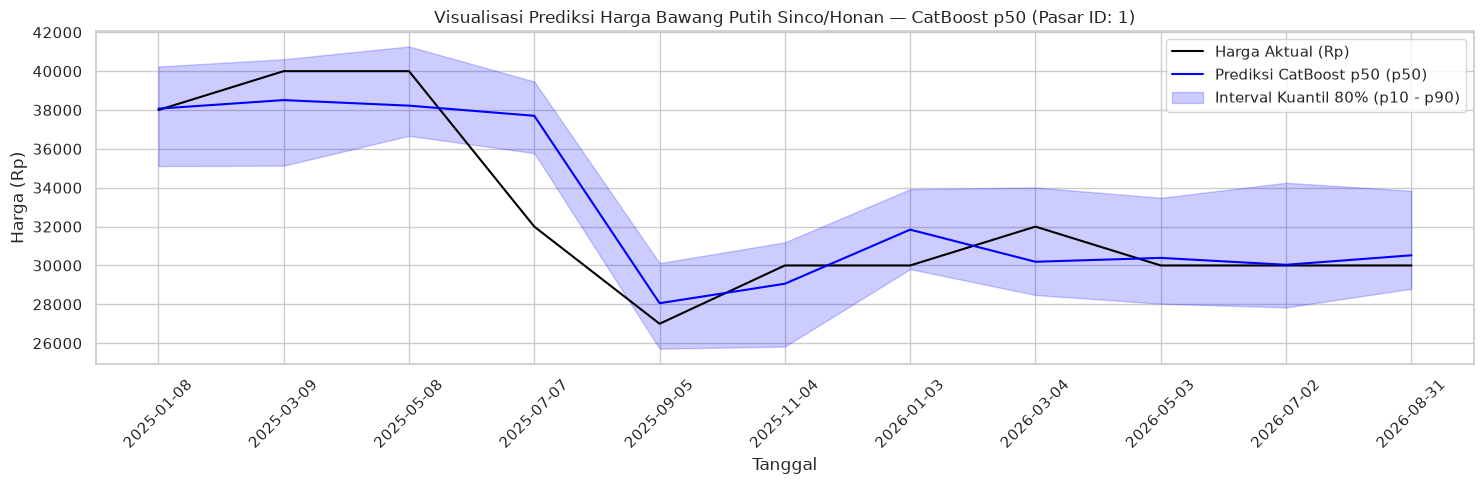

In [12]:
# Identifikasi model GBDT terbaik (WAPE terendah)
best_model_name = df_summary_e4.sort_values("WAPE (%)").iloc[0]["Model"]
print(f"🏆 Model GBDT Terbaik untuk {CANONICAL_NAME}: {best_model_name}")

# df_e4 sudah memiliki prediksi utama di kolom 'harga_prediksi'
df_best_gbdt = df_e4.copy()

# Opsional: Pastikan kolom 'harga_prediksi' sesuai dengan model terbaik
best_col = f"pred_{best_model_name.lower().replace(' ', '_')}"
if best_col in df_best_gbdt.columns:
    df_best_gbdt["harga_prediksi"] = df_best_gbdt[best_col]

# Visualisasi kurva aktual vs median prediksi beserta interval kuantil 80% (p10 - p90)
target_market_id = 1 if 1 in df_best_gbdt["pasar_id"].values else df_best_gbdt["pasar_id"].iloc[0]
df_plot = df_best_gbdt[df_best_gbdt["pasar_id"] == target_market_id].sort_values("tanggal")

plt.figure(figsize=(15, 5))
plt.plot(df_plot["tanggal"], df_plot["harga_aktual"], label="Harga Aktual (Rp)", color="black", linewidth=1.5)
plt.plot(df_plot["tanggal"], df_plot["harga_prediksi"], label=f"Prediksi {best_model_name} (p50)", color="blue", linewidth=1.5)
if "batas_bawah" in df_plot.columns and "batas_atas" in df_plot.columns:
    plt.fill_between(df_plot["tanggal"], df_plot["batas_bawah"], df_plot["batas_atas"], color="blue", alpha=0.2, label="Interval Kuantil 80% (p10 - p90)")
plt.title(f"Visualisasi Prediksi Harga {CANONICAL_NAME} — {best_model_name} (Pasar ID: {target_market_id})")
plt.xlabel("Tanggal")
plt.ylabel("Harga (Rp)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 🧪 E5 — Studi Ablasi Fitur (Weather & Calendar Impact)
**Tujuan**: Menguji signifikansi empiris fitur eksternal cuaca BMKG dan kalender keagamaan/nasional terhadap akurasi arah (*Directional Accuracy*) dan WAPE menggunakan model GBDT terpilih.

In [13]:
print(f"\n--- E5: Studi Ablasi Fitur — {CANONICAL_NAME} ---")
engine = ForecastEngine(commodity_name=KOMODITAS, horizon=7, window_step_days=60)
target_model = "lightgbm" if "lightgbm" in best_model_name.lower() else ("xgboost" if "xgboost" in best_model_name.lower() else "catboost")
df_ablation = engine.run_ablation_study(model_type=target_model, verbose=False)
display(df_ablation)



--- E5: Studi Ablasi Fitur — Bawang Putih Sinco/Honan ---


,Configuration,Weather,Calendar,WAPE (%),MAE (Rp),Directional Accuracy (%),PICP (%),RMSE (Rp),sMAPE (%)
0,Full Features (Price + Calendar + Weather),Yes,Yes,4.15,1424.41,30.30,78.79,2154.98,4.09
1,Ablation: Without Weather,No,Yes,3.87,1329.21,24.24,78.79,2090.75,3.86
2,Ablation: Without Calendar,Yes,No,3.87,1327.79,25.76,80.30,2074.83,3.82
3,Minimal (Price Lags Only),No,No,3.76,1290.03,36.36,78.79,2079.44,3.74


## 🚨 E6 — Kalibrasi & Evaluasi Sistem Early Warning (EWS)
Sesuai kerangka metodologi `docs/EWS_methodology.md`, luaran peramalan kuantil ditransformasikan ke dalam skor risiko komposit 100-poin (20-20-20-40):
* **Pilar 1 (20 poin)**: Skor Tren Historis (Kenaikan 7 hari terakhir)
* **Pilar 2 (20 poin)**: Skor Volatilitas Pasar (Rasio Std 7h / Std 30h)
* **Pilar 3 (20 poin)**: Skor Disparitas Pasar Grosir vs Eceran (Kolaps Margin Pasar Keputran)
* **Pilar 4 (40 poin)**: Skor Proyeksi Bahaya Masa Depan (Median Naik ≥15% dan Q90 Tembus Rekor 90-Hari)

Kinerja deteksi dini dievaluasi terhadap krisis lonjakan harga aktual menggunakan metrik **Recall (Target ≥90%)**, **False Alarm Rate (Target ≤20%)**, dan **Lead Time (Target ≥5–7 Hari)**.

In [14]:
print(f"\n--- E6: Kalibrasi & Evaluasi EWS — {CANONICAL_NAME} ---")

# 1. Hitung skor risiko komposit 20-20-20-40 dan status peringatan (NORMAL / WASPADA / TINGGI)
df_ews = generate_ews_summary_dataframe(df_best_gbdt)
print("Sampel Status EWS Pasar:")
display(df_ews.tail(10))

# 2. Evaluasi Kinerja Anomaly Detection EWS (Recall, False Alarm Rate, Lead Time)
scorecard_ews = evaluate_ews_performance(df_ews, spike_threshold_pct=10.0, alarm_level="TINGGI", horizon_days=7)
print("\nMatriks Kinerja & Validasi Target SOP EWS:")
display(scorecard_ews)



--- E6: Kalibrasi & Evaluasi EWS — Bawang Putih Sinco/Honan ---
Sampel Status EWS Pasar:


,tanggal,pasar_id,nama_pasar,komoditas_id,tanggal_origin,harga_aktual,price_current,harga_prediksi,skor_tren,skor_volatilitas,skor_anomali,skor_prediksi,total_skor,status_warning
56,2026-07-02,3,Pasar Genteng,49,2026-06-25,36000,37000,35742,10,0,0,0,10,NORMAL
57,2026-07-02,4,Pasar Pucang Anom,49,2026-06-25,30000,35000,36253,0,0,0,0,0,NORMAL
58,2026-07-02,5,Pasar Keputran,49,2026-06-25,35000,35000,33416,20,0,0,0,20,NORMAL
59,2026-07-02,146,Pasar Soponyono,49,2026-06-25,33000,33000,32978,0,0,0,0,0,NORMAL
60,2026-08-31,1,Pasar Tambahrejo,49,2026-08-24,30000,30000,30523,0,0,0,0,0,NORMAL
61,2026-08-31,2,Pasar Wonokromo,49,2026-08-24,32000,35000,34569,20,0,0,0,20,NORMAL
62,2026-08-31,3,Pasar Genteng,49,2026-08-24,30000,30000,30003,0,0,0,0,0,NORMAL
63,2026-08-31,4,Pasar Pucang Anom,49,2026-08-24,40000,33000,36071,0,0,0,0,0,NORMAL
64,2026-08-31,5,Pasar Keputran,49,2026-08-24,35000,35000,34837,0,0,0,0,0,NORMAL
65,2026-08-31,146,Pasar Soponyono,49,2026-08-24,35000,33000,33004,0,0,0,0,0,NORMAL



Matriks Kinerja & Validasi Target SOP EWS:


,Metrik,Nilai,Target SOP,Status
0,Recall (Sensitivitas Krisis),0.0%,>= 90.0%,PERLU PENYESUAIAN
1,False Alarm Rate (FAR),0.0%,<= 20.0%,MEMENUHI TARGET
2,Lead Time Peringatan,7 Hari (H+7),>= 5 - 7 Hari,MEMENUHI TARGET
3,Precision,0.0%,N/A,INFO
4,True Positives (Krisis Terdeteksi),0,N/A,INFO
5,False Negatives (Krisis Luput),2,Minimal (0),INFO
6,False Positives (Alarm Palsu),0,Minimal,INFO
7,Total Observasi Evaluasi,66,N/A,INFO


## 📉 Diagnostik Galat & Analisis Residu
Memeriksa distribusi galat prediksi dan korelasi serial residu untuk memastikan tidak ada pola tersisa yang belum tertangkap oleh model.

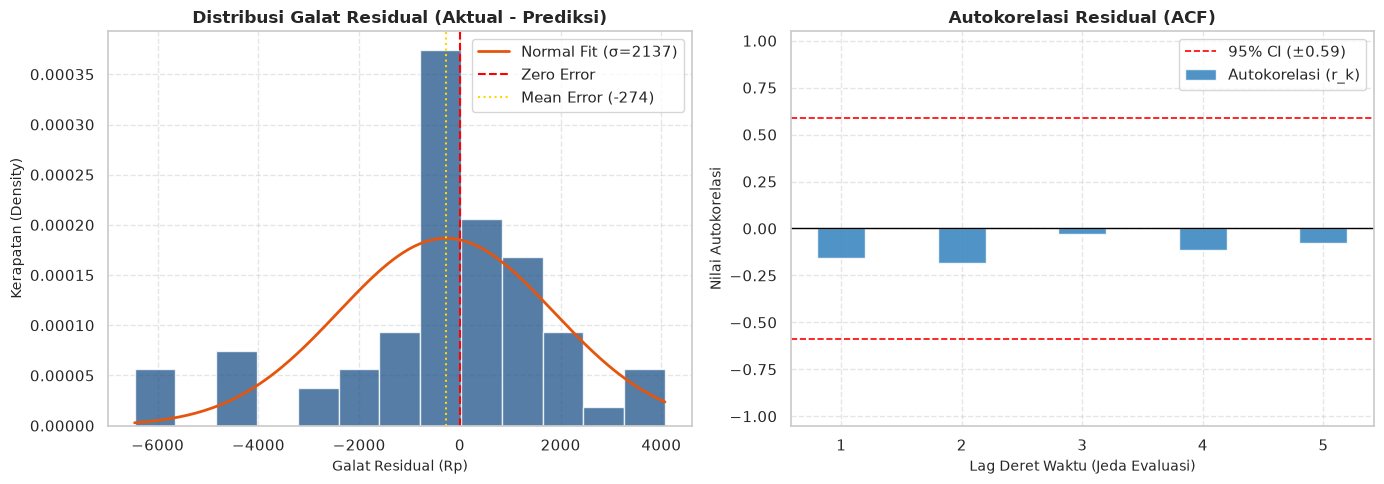

In [15]:
fig = plot_residual_diagnostics(df_best_gbdt)
plt.show()


## 📝 E7 — Pencatatan Eksperimen ke Weights & Biases (W&B)
Sel ini mencatat seluruh rangkaian eksperimen dari notebook ini (Komparasi GBDT E4, Studi Ablasi E5, dan Scorecard Validasi EWS E6) langsung ke dashboard cloud **Weights & Biases (W&B)**.


In [ ]:
print(f"\n--- E7: Log Eksperimen Notebook ke Weights & Biases (W&B) — {CANONICAL_NAME} ---")

# Inisialisasi engine dan catat seluruh artefak eksperimen ke W&B
engine = ForecastEngine(commodity_name=KOMODITAS)
run = engine.log_notebook_experiment(
    df_summary_gbdt=df_summary_e4 if "df_summary_e4" in locals() else None,
    df_ablation=df_ablation if "df_ablation" in locals() else None,
    scorecard_ews=scorecard_ews if "scorecard_ews" in locals() else None,
    df_predictions=df_best_gbdt if "df_best_gbdt" in locals() else None,
    run_name=f"Notebook-{CANONICAL_NAME.replace(' ', '_')}"
)
